# Домашнее задание: SFT для function calling

Qwen2.5-0.5B-Instruct умеет вызывать функции в формате `<tool_call>`, но наши пять функций умного дома видит
впервые и обращается с ними вольно. Дообучим её целиком (все веса) на диалогах с умным домом
и в конце посмотрим, как она управляет симулятором.

| Блок | Баллы |
|---|---|
| 1. До обучения: генерация через chat template | 1 |
| 2. Данные: разбор примера и роль каждого сообщения | 2 |
| 3. Маска loss: теги `{% generation %}` в шаблоне | 2 |
| 4. Обучение | 3 |
| 5. Оценка на тест-сете (дано) | 0 |
| 6. Агентный цикл | 2 |

Дано и менять не нужно: `smart_home.py` (симулятор и схемы пяти функций), `chat_ui.py` (чат),
`data/` с `train.jsonl`, `validation.jsonl` и `test_cases.jsonl`.
Ячейки для заполнения помечены `YOUR CODE HERE`.

## 0. Окружение

Берём Instruct-модель: формат `<tool_call>` и токен конца реплики `<|im_end|>` она уже знает,
учить будем поведению с конкретными функциями.

In [1]:
import gc
import hashlib
import importlib.metadata
import json
import os
import platform
import re
import subprocess
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import Dataset
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import SFTConfig, SFTTrainer

from chat_ui import launch_chat
from smart_home import BASELINE_PROMPTS, SMART_HOME_TOOLS, SYSTEM_PROMPT, SmartHome

SEED = 42
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
OUTPUT_DIR = Path("outputs/full_sft")
MAX_LENGTH = 2048
set_seed(SEED)
torch.set_num_threads(8)
assert torch.cuda.is_available(), "Нужен GPU kernel"
assert torch.cuda.device_count() == 2, "Запуск: CUDA_VISIBLE_DEVICES=0,1"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 200)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME, dtype=torch.bfloat16, attn_implementation="sdpa"
).to("cuda:0")
provenance = {
    "started_at_utc": datetime.now(timezone.utc).isoformat(),
    "hostname": platform.node(), "seed": SEED,
    "model": MODEL_NAME, "model_revision": model.config._commit_hash,
    "python": platform.python_version(), "cuda_runtime": torch.version.cuda,
    "packages": {p: importlib.metadata.version(p) for p in
                 ["torch", "transformers", "trl", "datasets", "accelerate"]},
    "gpus": [torch.cuda.get_device_name(i) for i in range(2)],
    "data_sha256": {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                    for p in sorted(Path("data").glob("*.jsonl"))},
}
print(json.dumps(provenance, ensure_ascii=False, indent=2))

{
  "started_at_utc": "2026-10-27T09:16:54.125197+00:00",
  "hostname": "edu-03",
  "seed": 42,
  "model": "Qwen/Qwen2.5-0.5B-Instruct",
  "model_revision": "7ae557604adf67be50417f59c2c2f167def9a775",
  "python": "3.12.3",
  "cuda_runtime": "12.6",
  "packages": {
    "torch": "2.8.0+cu126",
    "transformers": "4.56.1",
    "trl": "0.23.1",
    "datasets": "3.6.0",
    "accelerate": "1.6.0"
  },
  "gpus": [
    "NVIDIA A100-SXM4-80GB",
    "NVIDIA A100-SXM4-80GB"
  ],
  "data_sha256": {
    "test_cases.jsonl": "778e161d6d79b1064eacbe4a25c0e51b39c19128892fcb6dbea2573932c78b0c",
    "train.jsonl": "3ce307895527fe614c8738c32bb67d03a9559ae8e76bed8d854999f15d253d33",
    "validation.jsonl": "57ffc6406375f6bbf20b21dac0d8d82a1ca30160ddb4d81ffe24a69e876ef1d8"
  }
}


## 1. До обучения · 1 балл

Функция для модели — это JSON Schema: имя, описание, аргументы с типами и ограничениями.
Схемы передаются в `apply_chat_template` параметром `tools`: шаблон вставит их в system-реплику
и объяснит модели формат ответа `<tool_call>`. Посмотрим, что именно получает модель на вход.

In [2]:
print(json.dumps(SMART_HOME_TOOLS[0], ensure_ascii=False, indent=2))
print("=" * 80)
messages = [
    {"role": "system", "content": SYSTEM_PROMPT},
    {"role": "user", "content": "Turn on the kitchen light."},
]
print(tokenizer.apply_chat_template(messages, tools=SMART_HOME_TOOLS, tokenize=False, add_generation_prompt=True))

{
  "type": "function",
  "function": {
    "name": "turn_light",
    "description": "Switch a room light on or off. Ask for the room if unknown.",
    "parameters": {
      "type": "object",
      "properties": {
        "room": {
          "type": "string",
          "enum": [
            "kitchen",
            "bedroom",
            "living_room"
          ]
        },
        "state": {
          "type": "string",
          "enum": [
            "on",
            "off"
          ]
        }
      },
      "required": [
        "room",
        "state"
      ],
      "additionalProperties": false
    }
  }
}
<|im_start|>system
You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"n

**Задание (1 балл).** Напишите `generate`: сообщения и схемы функций проходят через `apply_chat_template`
с `add_generation_prompt=True`, декодирование жадное, стоп на `<|im_end|>` (это `eos_token` токенизатора).
Верните только новые токены, без спецтокенов. Эта функция используется во всех следующих блоках.

In [3]:
@torch.inference_mode()
def generate(model, tokenizer, messages, tools, max_new_tokens=256):
    model.eval()
    inputs = tokenizer.apply_chat_template(
        messages, tools=tools, add_generation_prompt=True,
        tokenize=True, return_dict=True, return_tensors="pt",
    ).to(next(model.parameters()).device)
    output = model.generate(
        **inputs, max_new_tokens=max_new_tokens, do_sample=False,
        eos_token_id=tokenizer.convert_tokens_to_ids("<|im_end|>"),
        pad_token_id=tokenizer.pad_token_id,
    )
    new_tokens = output[0, inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True)


def answer(model, tokenizer, prompt):
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": prompt}]
    return generate(model, tokenizer, messages, SMART_HOME_TOOLS)

Формат модель знает, поэтому простые запросы отработает правильно. Смотрите на сложные: «Open the garage» —
модель подставляет в `turn_light` комнату `garage`, которой нет в схеме; «Turn off all lights» — придумывает
`room: "all"` вместо трёх вызовов; «Turn on the light» — выбирает комнату сама вместо уточняющего вопроса.
Запомним её ответы на десять запросов, после обучения сравним.

In [4]:
comparison = pd.DataFrame({"prompt": BASELINE_PROMPTS})
comparison["base"] = [answer(model, tokenizer, prompt) for prompt in BASELINE_PROMPTS]
display(comparison)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


,prompt,base
0,Turn on the kitchen light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>"
1,Set the bedroom to 23 degrees.,"<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>"
2,What is the state of the living room?,"<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>"
3,Add two cartons of milk to my shopping list.,"<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk"", ""quantity"": 2}}\n</tool_call>"
4,Set a 10-minute timer labeled pasta.,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>"
5,Turn off the bedroom light and set its temperature to 20 degrees.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool..."
6,Turn off all lights.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""all"", ""state"": ""off""}}\n</tool_call>"
7,Hello!,How can I help you today?
8,Open the garage.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""garage"", ""state"": ""on""}}\n</tool_call>"
9,Turn on the light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""on""}}\n</tool_call>"


## 2. Данные · 2 балла

Чтобы модель вызывала функции, покажем ей диалоги, где это делается правильно.
Одна строка JSONL — один диалог: `messages` и `tools`. Вызов функции — поле `tool_calls`
у реплики assistant, результат функции — отдельное сообщение с ролью `tool`.

In [5]:
def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]


def show_dialog(messages):
    for message in messages:
        print(f"[{message['role']}] {message.get('content', '')}")
        for call in message.get("tool_calls") or []:
            arguments = json.dumps(call["function"]["arguments"], ensure_ascii=False)
            print(f"    -> {call['function']['name']}({arguments})")


train_rows = read_jsonl("data/train.jsonl")
validation_rows = read_jsonl("data/validation.jsonl")
print(f"train: {len(train_rows)}, validation: {len(validation_rows)}\n")

example = next(row for row in train_rows if any(m.get("tool_calls") for m in row["messages"]))
show_dialog(example["messages"])

def context(messages):
    return messages[1:] if messages and messages[0]["role"] == "system" else messages

def message_key(messages):
    return json.dumps(messages, sort_keys=True, ensure_ascii=False, separators=(",", ":"))

data_overlap = []
audit_cases = read_jsonl("data/test_cases.jsonl")
for split, rows in [("train", train_rows), ("validation", validation_rows)]:
    prefixes = {}
    for row in rows:
        ms = context(row["messages"])
        for stop, message in enumerate(ms, 1):
            if message["role"] in ("user", "tool"):
                prefixes.setdefault(message_key(ms[:stop]), []).append(row["id"])
    for case in audit_cases:
        matches = prefixes.get(message_key(context(case["messages"])), [])
        if matches:
            data_overlap.append({"split": split, "test_id": case["id"], "source_ids": matches})
scenario_overlap = {r["scenario_id"] for r in train_rows} & {r["scenario_id"] for r in validation_rows}
assert not scenario_overlap
print("Пересечение train/validation по scenario_id:", len(scenario_overlap))
print("Совпадение контекстов официального теста с train/validation:")
display(pd.DataFrame(data_overlap))
provenance["test_context_overlap"] = data_overlap


train: 831, validation: 91

[system] You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.
[user] Сделай в гостиной 40 градусов, гости мерзнут
[assistant] Выше 30 градусов поставить нельзя, диапазон 16-30. Поставить в гостиной 30?
[user] Хорошо, тогда максимум
[assistant] 
    -> set_temperature({"room": "living_room", "value": 30})
[tool] {"room": "living_room", "light": "off", "temperature": 30}
[assistant] Готово, в гостиной теперь 30 градусов.
Пересечение train/validation по scenario_id: 0
Совпадение контекстов официального теста с train/validation:


,split,test_id,source_ids
0,train,en_17,[train_0257]
1,train,en_22,[train_0821]
2,train,ru_13,[train_0310]
3,validation,en_27,[validation_0078]


В данных четыре типа диалогов. Примеры без вызова — не балласт: это единственное место, где модель видит,
что на неподдерживаемый запрос («открой гараж», «какая погода») нужно ответить отказом, а не подобрать
ближайшую функцию.

In [6]:
def scenario_type(row):
    calls_per_message = [len(m.get("tool_calls") or []) for m in row["messages"]]
    if sum(calls_per_message) == 0:
        return "no_call"
    if sum(n > 0 for n in calls_per_message) > 1:
        return "multi_turn"
    return "parallel_calls" if max(calls_per_message) > 1 else "single_call"


pd.DataFrame({
    "train": pd.Series([scenario_type(row) for row in train_rows]).value_counts(),
    "validation": pd.Series([scenario_type(row) for row in validation_rows]).value_counts(),
})

,train,validation
multi_turn,219,22
no_call,144,16
parallel_calls,145,15
single_call,323,38


Тот же диалог после шаблона — ровно такой текст модель увидит на обучении. `tool_calls` стали блоками
`<tool_call>` внутри реплики assistant, а результат функции — блоком `<tool_response>` внутри реплики
**user**: для модели это входящая информация, как и вопрос пользователя.

In [7]:
print(tokenizer.apply_chat_template(example["messages"], tools=example["tools"], tokenize=False))

<|im_start|>system
You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"name": "turn_light", "description": "Switch a room light on or off. Ask for the room if unknown.", "parameters": {"type": "object", "properties": {"room": {"type": "string", "enum": ["kitchen", "bedroom", "living_room"]}, "state": {"type": "string", "enum": ["on", "off"]}}, "required": ["room", "state"], "additionalProperties": false}}}
{"type": "function", "function": {"name": "set_temperature", "description": "Set an absolute room temperature in Celsius. For relative changes, obtain the current temperature first.", "parameters": {"type": "object", "properties": {"room": {"type": "string", "enum": ["kitchen", "

### Ваш разбор · 2 балла
Ответьте текстом по ячейкам выше:
- **1 балл.** В тексте после шаблона результат функции оказался внутри реплики **user**, а не assistant.
  Почему формат устроен так и что пошло бы не так, если бы модель училась предсказывать содержимое
  `<tool_response>` наравне со своими репликами?
- **1 балл.** По таблице типов сценариев: какой навык function calling даёт каждый из четырёх типов
  и чему модель не научится, если какой-то тип убрать из данных?


Результат функции — наблюдение из внешней среды, которое модель получает, а не генерирует.
В нативном шаблоне Qwen сообщения `tool` упакованы в `user` с тегами `<tool_response>`.
Роль `tool` при этом остаётся в исходной структуре диалога. На следующем шаге ассистент
использует результат как контекст: например, прочитанную температуру — для расчёта новой.

Если обучать и на содержимом `<tool_response>`, градиенты будут тратиться на предсказание
внешних наблюдений, хотя на инференсе их сообщает симулятор. Это создаёт лишнюю задачу и
может поощрять имитацию результатов. Само по себе включение этих токенов в loss не означает,
что агент обязательно обойдёт симулятор: исполнение задаёт программа. Правильная граница
супервизии здесь — только решения и реплики assistant.

| Тип | Навык | Что теряется без него |
|---|---|---|
| `single_call` | Выбор одной функции и заполнение аргументов | Базовое соответствие запроса схеме инструмента |
| `parallel_calls` | Несколько вызовов в одной реплике | Разложение составной команды, в том числе по всем комнатам |
| `multi_turn` | Использование результата функции и истории | Зависимые действия, относительные изменения, продолжение диалога |
| `no_call` | Обычный ответ, уточнение или отказ без инструмента | Умение воздержаться от неподдерживаемого или преждевременного действия |

Эти навыки частично пересекаются; удаление типа не доказывает полную потерю навыка,
но убирает прямую супервизию соответствующего поведения.


## 3. Маска loss · 2 балла

В тексте выше модель должна учиться только своим репликам: тексту, `<tool_call>` и `<|im_end|>`.
Запрос пользователя и результат функции она читает, но не предсказывает — у этих токенов label `-100`.
За это в TRL отвечает `assistant_only_loss=True`, а маску он строит по тегам
`{% generation %}…{% endgeneration %}` в chat template. В нативном шаблоне Qwen их нет.

In [8]:
NATIVE_TEMPLATE = tokenizer.chat_template
print(NATIVE_TEMPLATE)

{%- if tools %}
    {{- '<|im_start|>system\n' }}
    {%- if messages[0]['role'] == 'system' %}
        {{- messages[0]['content'] }}
    {%- else %}
        {{- 'You are Qwen, created by Alibaba Cloud. You are a helpful assistant.' }}
    {%- endif %}
    {{- "\n\n# Tools\n\nYou may call one or more functions to assist with the user query.\n\nYou are provided with function signatures within <tools></tools> XML tags:\n<tools>" }}
    {%- for tool in tools %}
        {{- "\n" }}
        {{- tool | tojson }}
    {%- endfor %}
    {{- "\n</tools>\n\nFor each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\n<tool_call>\n{\"name\": <function-name>, \"arguments\": <args-json-object>}\n</tool_call><|im_end|>\n" }}
{%- else %}
    {%- if messages[0]['role'] == 'system' %}
        {{- '<|im_start|>system\n' + messages[0]['content'] + '<|im_end|>\n' }}
    {%- else %}
        {{- '<|im_start|>system\nYou are Qwen, created by Alibaba C

**Задание (2 балла).** Оберните в `{% generation %}…{% endgeneration %}` вывод реплик assistant — и текст,
и `tool_calls` — и присвойте результат в `tokenizer.chat_template`. Текст, который рендерит шаблон,
меняться не должен: теги влияют только на маску. Ячейка после задания проверит и то, и другое,
и напечатает токены, по которым будет считаться loss.

In [9]:
# Разделяем обычные assistant-реплики и assistant с tool_calls.
# Генерационные теги не добавляют символов в отрендеренный диалог.
old_plain = r"""    {%- if (message.role == "user") or (message.role == "system" and not loop.first) or (message.role == "assistant" and not message.tool_calls) %}
        {{- '<|im_start|>' + message.role + '\n' + message.content + '<|im_end|>' + '\n' }}
    {%- elif message.role == "assistant" %}"""
new_plain = r"""    {%- if (message.role == "user") or (message.role == "system" and not loop.first) %}
        {{- '<|im_start|>' + message.role + '\n' + message.content + '<|im_end|>' + '\n' }}
    {%- elif message.role == "assistant" and not message.tool_calls %}
        {{- '<|im_start|>' + message.role + '\n' }}{% generation %}{{- message.content + '<|im_end|>' + '\n' }}{% endgeneration %}
    {%- elif message.role == "assistant" %}"""
assert NATIVE_TEMPLATE.count(old_plain) == 1, "Изменился нативный шаблон: требуется проверка"
TRAIN_TEMPLATE = NATIVE_TEMPLATE.replace(old_plain, new_plain)
tool_start = "{{- '<|im_start|>' + message.role }}"
tool_end = r"{{- '<|im_end|>\n' }}" + '\n    {%- elif message.role == "tool" %}'
assert TRAIN_TEMPLATE.count(tool_start) == 1 and TRAIN_TEMPLATE.count(tool_end) == 1
TRAIN_TEMPLATE = TRAIN_TEMPLATE.replace(tool_start, tool_start + "{% generation %}")
TRAIN_TEMPLATE = TRAIN_TEMPLATE.replace(
    tool_end, r"{{- '<|im_end|>\n' }}{% endgeneration %}" + '\n    {%- elif message.role == "tool" %}'
)
tokenizer.chat_template = TRAIN_TEMPLATE

In [10]:
rendered = tokenizer.apply_chat_template(example["messages"], tools=example["tools"], tokenize=False)
assert rendered == tokenizer.apply_chat_template(
    example["messages"], tools=example["tools"], tokenize=False, chat_template=NATIVE_TEMPLATE
), "Теги изменили текст шаблона"

encoded = tokenizer.apply_chat_template(
    example["messages"], tools=example["tools"],
    tokenize=True, return_dict=True, return_assistant_tokens_mask=True,
)
trained = tokenizer.decode([token for token, flag in zip(encoded["input_ids"], encoded["assistant_masks"]) if flag])
assert "<tool_call>" in trained and "<|im_end|>" in trained, "Реплики assistant не попали в маску"
assert "<tools>" not in trained and "<tool_response>" not in trained, "В маске лишние токены"
print(f"учим {sum(encoded['assistant_masks'])} из {len(encoded['input_ids'])} токенов:\n")
print(trained)

# Проверяем все диалоги, включая обычный текст и несколько tool-ответов подряд.
lengths = []
supervised = []
for row in train_rows + validation_rows:
    native = tokenizer.apply_chat_template(row["messages"], tools=row["tools"], tokenize=False,
                                           chat_template=NATIVE_TEMPLATE)
    patched = tokenizer.apply_chat_template(row["messages"], tools=row["tools"], tokenize=False)
    assert native == patched, row["id"]
    enc = tokenizer.apply_chat_template(row["messages"], tools=row["tools"],
                                       return_dict=True, return_assistant_tokens_mask=True)
    trained_text = tokenizer.decode([t for t, flag in zip(enc["input_ids"], enc["assistant_masks"]) if flag])
    assert sum(enc["assistant_masks"]) > 0, row["id"]
    assert "<tool_response>" not in trained_text and "<tools>" not in trained_text, row["id"]
    assert "<|im_start|>" not in trained_text, row["id"]
    n_assistant = sum(m["role"] == "assistant" for m in row["messages"])
    assert trained_text.count("<|im_end|>") == n_assistant, row["id"]
    lengths.append(len(enc["input_ids"]))
    supervised.append(sum(enc["assistant_masks"]))
assert max(lengths) <= MAX_LENGTH, "Нельзя молча обрезать диалоги"
print(f"Проверены {len(lengths)} диалога: native == train; max_length={max(lengths)}")
print(pd.Series(lengths).describe())
print(f"Доля обучаемых токенов: {sum(supervised) / sum(lengths):.2%}")


учим 89 из 764 токенов:

Выше 30 градусов поставить нельзя, диапазон 16-30. Поставить в гостиной 30?<|im_end|>

<tool_call>
{"name": "set_temperature", "arguments": {"room": "living_room", "value": 30}}
</tool_call><|im_end|>
Готово, в гостиной теперь 30 градусов.<|im_end|>



Проверены 922 диалога: native == train; max_length=1285
count     922.000000
mean      758.093275
std       126.066077
min       611.000000
25%       685.000000
50%       715.500000
75%       788.000000
max      1285.000000
dtype: float64
Доля обучаемых токенов: 10.45%


## 4. Обучение · 3 балла

Данные и маска готовы. `SFTTrainer` сам применит шаблон к `messages` и `tools`, а `assistant_only_loss=True`
возьмёт маску из ваших тегов. Обучаем все веса модели.

In [11]:
def drop_nulls(value):
    if isinstance(value, dict):
        return {key: drop_nulls(item) for key, item in value.items() if item is not None}
    if isinstance(value, list):
        return [drop_nulls(item) for item in value]
    return value


def to_dataset(rows):
    # Arrow приводит схемы всех функций к общей структуре и дописывает отсутствующим полям null,
    # из-за чего в JSON Schema появилось бы "enum": null. Убираем null при чтении примеров.
    dataset = Dataset.from_list([{"messages": row["messages"], "tools": row["tools"]} for row in rows])
    return dataset.with_transform(lambda batch: {key: [drop_nulls(item) for item in items] for key, items in batch.items()})


train_dataset = to_dataset(train_rows)
validation_dataset = to_dataset(validation_rows)

**Задание (3 балла).** Заполните `SFTConfig`, создайте `SFTTrainer`, обучите модель и сохраните её в `OUTPUT_DIR`
(`trainer.save_model()` сохранит и токенизатор с вашим шаблоном). Ориентир: 3 эпохи на 0.5B — пара минут на A100.

In [12]:
# Обучение на двух GPU запускается в train_distributed.py.
worker_path = Path("train_distributed.py")
assert worker_path.is_file(), "Запускайте notebook из папки hw3"
tokenizer.save_pretrained("outputs/tokenizer_for_training")
training_config = {
    "model_name": MODEL_NAME, "model_revision": provenance["model_revision"],
    "output_dir": str(OUTPUT_DIR), "seed": SEED, "max_length": MAX_LENGTH,
}
Path("outputs/training_config.json").write_text(json.dumps(training_config, indent=2))
del model
gc.collect()
torch.cuda.empty_cache()
subprocess.run([
    sys.executable, "-m", "torch.distributed.run", "--standalone", "--nproc_per_node=2",
    str(worker_path), "--config", "outputs/training_config.json",
], check=True, env={**os.environ, "CUDA_VISIBLE_DEVICES": "0,1", "OMP_NUM_THREADS": "8"})
training_state = json.loads((OUTPUT_DIR / "training_state.json").read_text())
assert training_state["world_size"] == 2 and training_state["status"] == "completed"
model = AutoModelForCausalLM.from_pretrained(
    OUTPUT_DIR, dtype=torch.bfloat16, attn_implementation="sdpa"
).to("cuda:0").eval()
saved_tokenizer = AutoTokenizer.from_pretrained(OUTPUT_DIR)
assert saved_tokenizer.chat_template == tokenizer.chat_template
provenance.update({k: training_state[k] for k in [
    "trainable_parameters", "training_seconds", "training_metrics", "peak_allocated_gib",
]})
provenance["config"] = {
    "epochs": 3, "learning_rate": 5e-5, "global_batch_size": 8,
    "assistant_only_loss": True, "max_length": MAX_LENGTH, "parallelism": "DistributedDataParallel",
}
Path("outputs/run_manifest.json").write_text(json.dumps(provenance, ensure_ascii=False, indent=2))
Path("outputs/training_state.json").write_text(json.dumps(training_state, ensure_ascii=False, indent=2))
print(f"Обучение: {training_state['training_seconds']:.1f} секунд; "
      f"peak GiB: {training_state['peak_allocated_gib']}")

Tokenizing train dataset:   6%|▋         | 54/831 [00:00<00:01, 510.24 examples/s]

Tokenizing train dataset:  21%|██        | 174/831 [00:00<00:01, 571.19 examples/s]

Tokenizing train dataset:  35%|███▌      | 293/831 [00:00<00:00, 579.00 examples/s]

Tokenizing train dataset:  49%|████▉     | 411/831 [00:00<00:00, 581.38 examples/s]

Tokenizing train dataset:  67%|██████▋   | 559/831 [00:00<00:00, 583.32 examples/s]

...


 67%|██████▋   | 8/12 [00:00<00:00, 15.17it/s]


 83%|████████▎ | 10/12 [00:00<00:00, 15.30it/s]
                                                 
100%|██████████| 312/312 [01:01<00:00,  5.10it/s]


{'eval_loss': 0.30267682671546936, 'eval_runtime': 0.813, 'eval_samples_per_second': 111.934, 'eval_steps_per_second': 14.76, 'eval_entropy': 0.5990127821763357, 'eval_num_tokens': 1896854.0, 'eval_mean_token_accuracy': 0.934174120426178, 'epoch': 3.0}
{'train_runtime': 61.1682, 'train_samples_per_second': 40.756, 'train_steps_per_second': 5.101, 'train_loss': 0.17064142867158621, 'epoch': 3.0}


COMPLETED: steps=312, seconds=61.32, peak_GiB=[19.66821813583374, 19.76108694076538]


Обучение: 61.3 секунд; peak GiB: [19.66821813583374, 19.76108694076538]


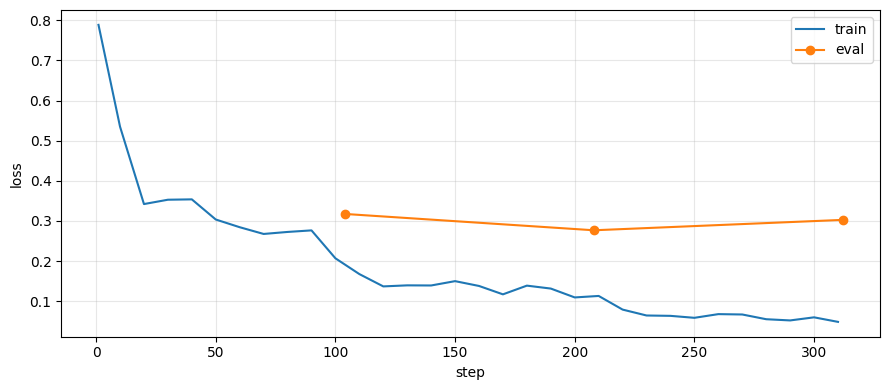

In [13]:
history = pd.DataFrame(training_state["log_history"])
train_log = history.dropna(subset=["loss"])
eval_log = history.dropna(subset=["eval_loss"])

plt.figure(figsize=(9, 4))
plt.plot(train_log["step"], train_log["loss"], label="train")
plt.plot(eval_log["step"], eval_log["eval_loss"], marker="o", label="eval")
plt.xlabel("step")
plt.ylabel("loss")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("outputs/loss.png", dpi=160)
plt.show()
history.to_csv("outputs/training_history.csv", index=False)

## 5. Оценка на тест-сете

Eval loss показывает, насколько хорошо модель предсказывает ответы в валидационных диалогах, но не отвечает
на главный вопрос: вызывает ли она нужные функции. Проверим напрямую на `data/test_cases.jsonl`: 60 запросов к умному дому
(40 EN, 20 RU) с ожидаемыми вызовами.
- `tool_set_accuracy` — совпал набор вызванных функций (для запросов без вызова — модель ничего не вызвала);
- `exact_match` — совпали ещё и аргументы.

Битый `<tool_call>` или невалидный JSON — ошибка.

In [14]:
TOOL_CALL_PATTERN = re.compile(r"<tool_call>\s*(.*?)\s*</tool_call>", re.DOTALL)


def parse_tool_calls(text):
    """Вызовы {name, arguments} из ответа модели. None — формат нарушен."""
    blocks = TOOL_CALL_PATTERN.findall(text)
    if len(blocks) != text.count("<tool_call>") or len(blocks) != text.count("</tool_call>"):
        return None
    if re.search(r"</?tool_call\b", TOOL_CALL_PATTERN.sub("", text)):
        return None
    try:
        calls = [json.loads(block) for block in blocks]
    except ValueError:
        return None
    if not all(isinstance(call, dict) and isinstance(call.get("name"), str) and isinstance(call.get("arguments"), dict) for call in calls):
        return None
    return [{"name": call["name"], "arguments": call["arguments"]} for call in calls]


ARGUMENT_DEFAULTS = {
    tool["function"]["name"]: {name: spec["default"] for name, spec in tool["function"]["parameters"]["properties"].items() if "default" in spec}
    for tool in SMART_HOME_TOOLS
}


def canonical(calls):
    """Вызовы как отсортированные строки; пропущенный аргумент со значением по умолчанию (quantity=1) равен явному."""
    filled = [{"name": c["name"], "arguments": {**ARGUMENT_DEFAULTS.get(c["name"], {}), **c["arguments"]}} for c in calls]
    return sorted(json.dumps(c, sort_keys=True) for c in filled)


def evaluate(model, tokenizer, cases):
    rows = []
    for case in cases:
        messages = case["messages"]
        if messages[0]["role"] != "system":
            messages = [{"role": "system", "content": SYSTEM_PROMPT}, *messages]
        output = generate(model, tokenizer, messages, SMART_HOME_TOOLS)
        calls = parse_tool_calls(output)
        tools_ok = calls is not None and {call["name"] for call in calls} == set(case["expected_tools"])
        rows.append({
            "id": case["id"], "lang": case["lang"], "output": output,
            "tools_ok": tools_ok,
            "args_ok": tools_ok and canonical(calls) == canonical(case["expected_calls"]),
        })
    return pd.DataFrame(rows)


def summarize(results):
    return results.groupby("lang").agg(tool_set_accuracy=("tools_ok", "mean"), exact_match=("args_ok", "mean"))

In [15]:
gc.collect()
torch.cuda.empty_cache()
model.eval()
cases = read_jsonl("data/test_cases.jsonl")
base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME, revision=provenance["model_revision"], dtype=torch.bfloat16, attn_implementation="sdpa"
).to("cuda:1")
base_results = evaluate(base_model, tokenizer, cases)
sft_results = evaluate(model, tokenizer, cases)
scores = pd.concat([
    summarize(base_results).assign(model="base"),
    summarize(sft_results).assign(model="sft"),
]).reset_index()[["model", "lang", "tool_set_accuracy", "exact_match"]]
all_predictions = pd.concat([base_results.assign(model="base"), sft_results.assign(model="sft")])
all_predictions.to_csv("outputs/eval_predictions.csv", index=False)
scores.to_csv("outputs/eval_results.csv", index=False)
overall = all_predictions.groupby("model").agg(
    n=("id", "size"), tool_set_accuracy=("tools_ok", "mean"), exact_match=("args_ok", "mean")
)
display(scores)
display(overall)
overlap_ids = {x["test_id"] for x in data_overlap}
nonoverlap = all_predictions.loc[~all_predictions["id"].isin(overlap_ids)].groupby("model").agg(
    n=("id", "size"), tool_set_accuracy=("tools_ok", "mean"), exact_match=("args_ok", "mean")
)
nonoverlap.to_csv("outputs/eval_nonoverlap.csv")
print("Дополнительно: 56 случаев без точного совпадения контекста с train/validation:")
display(nonoverlap)
print("Ошибки SFT:")
display(sft_results.loc[~sft_results["args_ok"], ["id", "output", "tools_ok", "args_ok"]])
del base_model
gc.collect()
torch.cuda.empty_cache()

,model,lang,tool_set_accuracy,exact_match
0,base,en,0.750,0.550
1,base,ru,0.750,0.200
2,sft,en,0.975,0.925
3,sft,ru,0.950,0.950


,n,tool_set_accuracy,exact_match
model,,,
base,60,0.750000,0.433333
sft,60,0.966667,0.933333


Дополнительно: 56 случаев без точного совпадения контекста с train/validation:


,n,tool_set_accuracy,exact_match
model,,,
base,56,0.732143,0.410714
sft,56,0.964286,0.928571


Ошибки SFT:


,id,output,tools_ok,args_ok
2,en_03,"I can't control the living room light. I can only handle the kitchen, bedroom and living room.",False,False
13,en_14,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 120, ""label"": ""laundry""}}\n</tool_call>",True,False
37,en_38,"<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 25}}\n</tool_call>",True,False
43,ru_04,Я могу ставить температуру только от 16 до 30 градусов. Какое значение поставить на кухне?,False,False


Те же десять запросов: base-модель и обученная.

In [16]:
comparison["after_sft"] = [answer(model, tokenizer, prompt) for prompt in BASELINE_PROMPTS]
display(comparison)
comparison.to_csv("outputs/comparison.csv", index=False)

,prompt,base,after_sft
0,Turn on the kitchen light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>"
1,Set the bedroom to 23 degrees.,"<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>","<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>"
2,What is the state of the living room?,"<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>","<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>"
3,Add two cartons of milk to my shopping list.,"<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk"", ""quantity"": 2}}\n</tool_call>","<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""cartons of milk""}}\n</tool_call>"
4,Set a 10-minute timer labeled pasta.,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>","<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>"
5,Turn off the bedroom light and set its temperature to 20 degrees.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool...","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool..."
6,Turn off all lights.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""all"", ""state"": ""off""}}\n</tool_call>","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_c..."
7,Hello!,How can I help you today?,"Hi! I can control lights and temperature in three rooms: kitchen, bedroom and living room."
8,Open the garage.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""garage"", ""state"": ""on""}}\n</tool_call>","I can't control the garage. I can turn the lights on or off in the kitchen, bedroom or living room, set room temperatures, add items to your shopping list or start timers."
9,Turn on the light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""on""}}\n</tool_call>","Which room: kitchen, bedroom or living room?"


## 6. Агентный цикл · 2 балла

Модель печатает `<tool_call>`, но сама ничего не выполняет. Чтобы свет действительно включился,
нужен цикл: ответ модели → парсим вызовы → выполняем в симуляторе → результаты добавляем в историю
сообщениями `tool` → снова спрашиваем модель. Останавливаемся, когда модель ответила без вызовов.
`max_steps` защищает от бесконечных вызовов.

**Задание (2 балла).** Напишите `run_agent`: функция дописывает в `messages` реплики assistant
(с `tool_calls` в формате данных) и сообщения `tool`, пока модель не ответит текстом или не кончатся шаги.
Проверка — пять сценариев ниже: один вызов, два вызова за ход, относительное изменение температуры
(сначала нужно прочитать состояние), ответ без вызова и неподдерживаемый запрос. Оцениваем цикл, а не модель:
каждый вызов выполнен, результат попал в историю, состояние дома соответствует сделанным вызовам,
на неподдерживаемом запросе вызовов нет.

In [17]:
def run_agent(model, tokenizer, home, messages, max_steps=4):
    for _ in range(max_steps):
        text = generate(model, tokenizer, messages, SMART_HOME_TOOLS)
        calls = parse_tool_calls(text)
        if calls is None:
            # Битый ответ сохраняем для диагностики, ничего из него не исполняем.
            messages.append({"role": "assistant", "content": text})
            raise ValueError("Невалидный формат tool_call")
        if not calls:
            messages.append({"role": "assistant", "content": text})
            return {"status": "completed"}
        messages.append({
            "role": "assistant",
            "content": TOOL_CALL_PATTERN.sub("", text).strip(),
            "tool_calls": [{"type": "function", "function": call} for call in calls],
        })
        for call in calls:
            result = home.call(call["name"], call["arguments"])
            messages.append({"role": "tool", "name": call["name"],
                             "content": json.dumps(result, ensure_ascii=False)})
    return {"status": "max_steps_reached"}

In [18]:
scenarios = [
    ["Turn on the kitchen light."],
    ["Turn on the kitchen light and set it to 23 degrees."],
    ["Make it two degrees warmer in the bedroom.", "Two more degrees."],
    ["Thanks!"],
    ["Open the garage."],
]
agent_results = []
for number, prompts in enumerate(scenarios, 1):
    home = SmartHome()
    initial = home.snapshot()
    messages = [{"role": "system", "content": SYSTEM_PROMPT}]
    statuses = []
    turn_snapshots = []
    for prompt in prompts:
        messages.append({"role": "user", "content": prompt})
        statuses.append(run_agent(model, tokenizer, home, messages))
        turn_snapshots.append(home.snapshot())
    calls = [c["function"] for m in messages for c in m.get("tool_calls", [])]
    results = [json.loads(m["content"]) for m in messages if m["role"] == "tool"]
    snapshot = home.snapshot()
    completed = all(s["status"] == "completed" for s in statuses)
    mechanical_ok = len(calls) == len(results) and not any("error" in x for x in results) and completed
    if number == 1:
        goal_ok = snapshot["rooms"]["kitchen"]["light"] == "on"
    elif number == 2:
        goal_ok = snapshot["rooms"]["kitchen"] == {"light": "on", "temperature": 23}
        goal_ok = goal_ok and any(len(m.get("tool_calls", [])) == 2 for m in messages)
    elif number == 3:
        goal_ok = [s["rooms"]["bedroom"]["temperature"] for s in turn_snapshots] == [23, 25]
        goal_ok = goal_ok and bool(calls) and calls[0]["name"] == "get_room_state"
    else:
        goal_ok = not calls and snapshot == initial
    agent_results.append({"scenario": number, "prompts": prompts, "statuses": statuses,
                          "mechanical_ok": mechanical_ok, "goal_ok": goal_ok,
                          "messages": messages, "snapshot": snapshot, "turn_snapshots": turn_snapshots})
    print("=" * 80)
    show_dialog(messages[1:])
    print(f"дом: {json.dumps(snapshot, ensure_ascii=False)}")
    print(f"Цикл: {mechanical_ok}; цель сценария: {goal_ok}; statuses={statuses}")
Path("outputs/agent_results.json").write_text(json.dumps(agent_results, ensure_ascii=False, indent=2))
display(pd.DataFrame([{k: r[k] for k in ["scenario", "mechanical_ok", "goal_ok"]} for r in agent_results]))

[user] Turn on the kitchen light.
[assistant] 
    -> turn_light({"room": "kitchen", "state": "on"})
[tool] {"room": "kitchen", "light": "on", "temperature": 21}
[assistant] The kitchen light is now on.
дом: {"rooms": {"kitchen": {"light": "on", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}
Цикл: True; цель сценария: True; statuses=[{'status': 'completed'}]


[user] Turn on the kitchen light and set it to 23 degrees.
[assistant] 
    -> turn_light({"room": "kitchen", "state": "on"})
    -> set_temperature({"room": "kitchen", "value": 23})
[tool] {"room": "kitchen", "light": "on", "temperature": 21}
[tool] {"room": "kitchen", "light": "on", "temperature": 23}
[assistant] The kitchen light is on and the temperature is set to 23.
дом: {"rooms": {"kitchen": {"light": "on", "temperature": 23}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}
Цикл: True; цель сценария: True; statuses=[{'status': 'completed'}]


[user] Make it two degrees warmer in the bedroom.
[assistant] 
    -> get_room_state({"room": "bedroom"})
[tool] {"room": "bedroom", "light": "off", "temperature": 21}
[assistant] 
    -> set_temperature({"room": "bedroom", "value": 23})
[tool] {"room": "bedroom", "light": "off", "temperature": 23}
[assistant] The bedroom was at 21, so I raised it to 23 degrees.
[user] Two more degrees.
[assistant] 
    -> set_temperature({"room": "bedroom", "value": 25})
[tool] {"room": "bedroom", "light": "off", "temperature": 25}
[assistant] Now it's 25 degrees in the bedroom.
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 25}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}
Цикл: True; цель сценария: True; statuses=[{'status': 'completed'}, {'status': 'completed'}]
[user] Thanks!
[assistant] Anytime!
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperat

[user] Open the garage.
[assistant] I can't control the garage. I can turn the lights on or off in the kitchen, bedroom or living room, set room temperatures, add items to your shopping list or start timers.
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}
Цикл: True; цель сценария: True; statuses=[{'status': 'completed'}]


,scenario,mechanical_ok,goal_ok
0,1,True,True
1,2,True,True
2,3,True,True
3,4,True,True
4,5,True,True


Тот же `run_agent` в чате: слева диалог и вызовы функций, справа состояние дома.
Попробуйте `Turn off all lights.`, `Add milk to my shopping list.`, `Set a 5-minute timer labeled tea.`

In [19]:
launch_chat(model, tokenizer, SmartHome(), run_agent)

## Интерпретация результатов

Loss — средняя отрицательная log-вероятность правильного следующего токена на размеченных
assistant-позициях. Его снижение показывает улучшение предсказания этих реплик, но не доказывает
успех выполнения команд. Поэтому отдельно измеряются выбор функций и точность аргументов,
а затем проверяется выполнение в симуляторе. Train loss усредняется по обучающим шагам,
validation loss считается на конце эпохи: точки нельзя считать полностью синхронными измерениями.

`tool_set_accuracy` сравнивает множества имён; число повторных вызовов и аргументы в ней не учитываются.
`exact_match` сравнивает вызовы с аргументами, не учитывая порядок и подставляя `quantity=1`.
Проверка тест-сета оценивает следующий ответ на предоставленную историю, а не весь агентный цикл.
Пять сценариев агента — отдельная небольшая проверка исполнения и состояния симулятора.

Параметры выбраны до оценки теста; тест не используется для обучения, выбора эпохи или подбора
гиперпараметров. Один seed и 60 запросов дают учебную оценку на этих данных, но не доказывают
надёжность на произвольных формулировках. Ошибки сохраняются в `eval_predictions.csv`.

В предоставленных файлах 3 тестовых контекста точно совпадают с префиксами обучающих диалогов
(`en_17`, `en_22`, `ru_13`), ещё 1 — с валидационным (`en_27`). Train и validation по `scenario_id`
не пересекаются. Официальный тест сохранён целиком; отдельно показаны метрики на остальных 56
контекстах. Это исключает найденные точные совпадения, но само по себе не устанавливает
независимость всех формулировок или семантических шаблонов.


In [20]:
print("Итог по всем 60 случаям:")
display(overall)
print(f"Агент: цели {sum(r['goal_ok'] for r in agent_results)}/5; "
      f"механика {sum(r['mechanical_ok'] for r in agent_results)}/5")
provenance["finished_at_utc"] = datetime.now(timezone.utc).isoformat()
provenance["overall_metrics"] = overall.reset_index().to_dict(orient="records")
provenance["agent_goal_passes"] = sum(r["goal_ok"] for r in agent_results)
Path("outputs/run_manifest.json").write_text(json.dumps(provenance, ensure_ascii=False, indent=2))

Итог по всем 60 случаям:


,n,tool_set_accuracy,exact_match
model,,,
base,60,0.750000,0.433333
sft,60,0.966667,0.933333


Агент: цели 5/5; механика 5/5


2216

## Разбор выполненного запуска

Все 494,032,768 параметров обучены за 61.3 с,
312 шагов, три эпохи, DDP на двух A100. Максимум выделенной памяти PyTorch:
19.67 и 19.76 GiB по GPU.

| Модель | Язык | Tool set accuracy | Exact match |
|---|---|---:|---:|
| base | en | 75.0% | 55.0% |
| base | ru | 75.0% | 20.0% |
| sft | en | 97.5% | 92.5% |
| sft | ru | 95.0% | 95.0% |

В целом exact match вырос с 26/60 до 56/60; выбор функций — с 45/60 до 58/60.
Validation loss по эпохам: 0.31744 → 0.27676 → 0.30268.
На третьей эпохе validation loss выше, чем на второй: дальнейшее снижение train loss уже не сопровождается улучшением validation loss. Это совместимо с началом переобучения. В дальнейшем стоит сохранять и выбирать checkpoint по validation loss. В этом запуске заранее заданные три эпохи завершены целиком; по результатам теста модель не перенастраивалась.

Четыре оставшиеся ошибки SFT: `en_03` — ложный отказ включить свет в гостиной;
`en_14` — 120 минут вместо 60; `en_38` — 25 градусов вместо 20+2=22;
`ru_04` — лишнее уточнение вместо установки допустимых 19 градусов.
Все ответы имели корректный формат; оставшиеся ошибки относятся к содержанию решений.

Все 5 сценариев агента завершились корректно: проверены результаты каждого вызова,
два вызова в одной реплике и последовательность температуры 21→23→25. При этом успех этих
сценариев не отменяет ошибку 20+2 в отдельном тестовом контексте.

В таблице десяти контрольных запросов видны исправления для `all lights`, гаража и отсутствующей
комнаты. Есть и регрессия: `two cartons of milk` стало `item="cartons of milk"` без `quantity=2`
(симулятор подставил бы 1). Улучшение средних метрик не означает улучшения каждого примера.

Три тестовых контекста совпадают с train, один — с validation. На остальных 56 контекстах SFT
получила exact match 52/56=92.86%, base — 23/56=41.07%. Это дополнительная проверка на точные
совпадения контекстов; она не доказывает независимость всех семантических шаблонов.